# Financial Analytics & EDA — AI Personal Finance and Smart Expense Predictor

**Author:** Asmi Zilpilwar (Team Member 01 — Financial Analytics & EDA)

## 1. Introduction

**Purpose.** This notebook explores the project's transaction data to understand how money comes in (income), goes out (expenses) and what is left (savings). It is descriptive analysis only — no machine learning or forecasting (that is a separate part of the project). The findings describe the spending patterns that the forecasting and dashboard parts will build on.

**Dataset.** The repository's synthetic dataset (no real private data): **150 anonymous users, Jan 2022 – Dec 2025, amounts in INR**. Each row of `transactions_clean.csv` is one transaction with a type (`income`, `expense`, `refund`, `transfer`), amount, category, date and payment status.

**Questions we want to answer**
1. How much is earned and spent, and how much is saved?
2. Which categories take the largest share of spending?
3. How do income, expenses and savings change month to month?
4. Which months stand out as unusually high or low?

## 2. Import Libraries
Only the four libraries the project needs for EDA: `pandas`/`numpy` for data work, `matplotlib`/`seaborn` for charts.

In [1]:
import calendar
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.width", 160)

# One colour per concept, used consistently in every chart
INCOME_C, EXPENSE_C, SAVINGS_C, NEG_C = "#2a6fb0", "#e07b39", "#2e9e6b", "#c0392b"

## 3. Load and Inspect Data

We load `data/processed/transactions_clean.csv`, the already quality-checked file produced by the preprocessing notebook. The path is found relative to this notebook, so it works for anyone who clones the repository.

In [2]:
# Find the repository root (the folder that contains data/processed), wherever the notebook is run from
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").exists())
DATA_FILE = REPO_ROOT / "data" / "processed" / "transactions_clean.csv"
OUT_DIR = REPO_ROOT / "outputs" / "eda"          # charts and summary table are saved here
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

raw = pd.read_csv(DATA_FILE)
print("Loaded:", DATA_FILE.relative_to(REPO_ROOT))
print("Shape :", raw.shape)

Loaded: data\processed\transactions_clean.csv
Shape : (67945, 33)


In [3]:
print("Columns:", list(raw.columns))
raw.dtypes.to_frame("dtype").T

Columns: ['transaction_id', 'user_id', 'transaction_date', 'transaction_time', 'transaction_type', 'amount', 'currency', 'category', 'subcategory', 'description', 'payment_method', 'merchant_name', 'merchant_category', 'account_type', 'is_recurring', 'recurring_frequency', 'is_essential', 'planned_or_unplanned', 'payment_status', 'transaction_channel', 'city', 'state', 'financial_year', 'month', 'month_name', 'quarter', 'day_of_week', 'weekend_flag', 'needs_or_wants', 'data_source', 'recurring_id', 'related_transaction_id', 'year']


,transaction_id,user_id,transaction_date,transaction_time,transaction_type,amount,currency,category,subcategory,description,...,month,month_name,quarter,day_of_week,weekend_flag,needs_or_wants,data_source,recurring_id,related_transaction_id,year
dtype,str,str,str,str,str,float64,str,str,str,str,...,int64,str,str,str,int64,str,str,str,str,int64


In [4]:
raw.head()

,transaction_id,user_id,transaction_date,transaction_time,transaction_type,amount,currency,category,subcategory,description,...,month,month_name,quarter,day_of_week,weekend_flag,needs_or_wants,data_source,recurring_id,related_transaction_id,year
0,TXN0000001,U0048,2022-01-01,01:24:16,transfer,"1,000.00",INR,Savings and Investments,recurring_deposit,Recurring deposit instalment,...,1,January,Q1,Saturday,1,savings,bank_statement_import,REC0048_16,NaN,2022
1,TXN0000002,U0150,2022-01-01,01:30:44,expense,118.00,INR,Financial Expenses,bank_fees,Bank service charges,...,1,January,Q1,Saturday,1,needs,bank_statement_import,NaN,NaN,2022
2,TXN0000003,U0101,2022-01-01,02:05:09,transfer,"4,000.00",INR,Savings and Investments,sip_mutual_fund,Mutual fund SIP contribution,...,1,January,Q1,Saturday,1,savings,bank_statement_import,REC0101_14,NaN,2022
3,TXN0000004,U0094,2022-01-01,04:13:47,transfer,"1,500.00",INR,Savings and Investments,recurring_deposit,Recurring deposit instalment,...,1,January,Q1,Saturday,1,savings,bank_statement_import,REC0094_27,NaN,2022
4,TXN0000005,U0052,2022-01-01,04:53:17,transfer,"10,000.00",INR,Savings and Investments,sip_mutual_fund,Mutual fund SIP contribution,...,1,January,Q1,Saturday,1,savings,bank_statement_import,REC0052_24,NaN,2022


In [5]:
missing = raw.isna().sum()
missing = missing[missing > 0].to_frame("missing_values")
missing["percent"] = 100 * missing["missing_values"] / len(raw)
print("Exact duplicate rows      :", raw.duplicated().sum())
print("Duplicate transaction IDs :", raw["transaction_id"].duplicated().sum())
missing

Exact duplicate rows      : 0
Duplicate transaction IDs : 0


,missing_values,percent
transaction_time,1875,2.76
merchant_name,753,1.11
recurring_frequency,27361,40.27
recurring_id,27361,40.27
related_transaction_id,67797,99.78


**Reading the missing values.** The only columns with gaps are optional ones (`transaction_time`, `merchant_name`, `recurring_*`, and `related_transaction_id`, which is only filled for refunds). According to the data dictionary these blanks are expected. None of them are needed for this analysis, so nothing is filled in. The columns we rely on (date, type, amount, category, status) are complete.

In [6]:
raw[["amount"]].describe().T

,count,mean,std,min,25%,50%,75%,max
amount,"67,945.00","10,627.55","19,367.07",60.00,967.00,"3,500.00","11,442.00","329,894.00"


## 4. Data Cleaning

We keep the raw table untouched and build a separate `df`. Every decision is printed so it can be explained in the review.

| Step | Decision |
|---|---|
| Dates | Convert to proper dates; add a `month` period (e.g. 2023-05) for grouping |
| Text | Strip spaces and fix capitalisation of `transaction_type` / `category` |
| Amounts | `amount` is a positive magnitude; the type gives its meaning, so we check all are > 0 |
| Type vs. category | Check income rows are `Income`, and expense rows are real spending categories |
| Failed payments | Excluded from totals (the dataset's own rule: failed rows never count) — shown below, not silently dropped |
| Refunds | Money returned for an earlier expense, so they are **subtracted** from spending |
| Transfers | Savings/investment and account transfers move money, they are **not** income or expense |

In [7]:
df = raw.copy()

# 1) Dates -> real datetime; month period for grouping
df["transaction_date"] = pd.to_datetime(df["transaction_date"], errors="coerce")
print("Unparseable dates:", df["transaction_date"].isna().sum())
df["month"] = df["transaction_date"].dt.to_period("M")

# 2) Standardise text labels
for col in ["transaction_type", "category", "payment_status"]:
    df[col] = df[col].astype(str).str.strip()
df["transaction_type"] = df["transaction_type"].str.lower()
df["payment_status"] = df["payment_status"].str.lower()

# 3) Validate amounts
print("Amounts <= 0 or missing:", ((df["amount"] <= 0) | df["amount"].isna()).sum())

# 4) Type / category consistency
non_spend = {"Income", "Transfers", "Savings and Investments"}
bad_income  = df[(df.transaction_type == "income")  & (df.category != "Income")]
bad_expense = df[(df.transaction_type == "expense") & (df.category.isin(non_spend))]
print("Income rows with a non-income category  :", len(bad_income))
print("Expense rows with a non-spending category:", len(bad_expense))

# 5) Failed payments: show, then exclude from totals
print("\nPayment status counts:\n", df["payment_status"].value_counts().to_string())
failed = df[df.payment_status == "failed"]
print("\nFailed rows by type (not counted in any total):\n", failed.groupby("transaction_type")["amount"].agg(["count", "sum"]).to_string())
df = df[df.payment_status == "completed"].copy()
print("\nRows used for analysis:", len(df))

Unparseable dates: 0
Amounts <= 0 or missing: 0
Income rows with a non-income category  : 0
Expense rows with a non-spending category: 0

Payment status counts:
 payment_status
completed    67639
failed         306

Failed rows by type (not counted in any total):
                   count          sum
transaction_type                    
expense             306 1,410,311.53

Rows used for analysis: 67639


In [8]:
# Suspicious values: unusually large single transactions. We FLAG them, we do not delete them.
def flag_extreme(g, k=3.0):
    q1, q3 = g["amount"].quantile([0.25, 0.75])
    return g["amount"] > q3 + k * (q3 - q1)

df["extreme_amount"] = df.groupby("transaction_type", group_keys=False).apply(flag_extreme)
print(df.groupby("transaction_type")["extreme_amount"].agg(["sum", "count"]).rename(columns={"sum": "flagged", "count": "rows"}))
df[df.extreme_amount & (df.transaction_type == "expense")].nlargest(5, "amount")[["transaction_date", "category", "subcategory", "amount"]]

                  flagged   rows
transaction_type                
expense              2349  51684
income                129  11115
refund                 10    148
transfer              173   4692


,transaction_date,category,subcategory,amount
66953,2025-12-06,Shopping,electronics,"329,894.00"
1065,2022-01-22,Shopping,electronics,"271,500.00"
7061,2022-06-05,Shopping,electronics,"264,084.00"
52239,2025-01-31,Shopping,electronics,"248,212.00"
50243,2024-12-14,Travel,hotel_stay,"245,138.00"


**Decision on large amounts.** Large transactions are common here because they are genuine purchases (e.g. electronics, hotel stays) and large salaries, so they are **kept** and only flagged. Removing them would understate real spending. Where they affect a result (monthly spikes), we point it out in the analysis.

In [9]:
income   = df[df.transaction_type == "income"]
expenses = df[df.transaction_type == "expense"]
refunds  = df[df.transaction_type == "refund"]

print(f"Income rows: {len(income):,} | Expense rows: {len(expenses):,} | Refund rows: {len(refunds):,} | Transfer rows (excluded): {(df.transaction_type=='transfer').sum():,}")

# Net expense by category = expenses minus refunds in the same category
cat_gross   = expenses.groupby("category")["amount"].sum()
cat_refund  = refunds.groupby("category")["amount"].sum().reindex(cat_gross.index, fill_value=0)
orphan = set(refunds.category) - set(cat_gross.index)
print("Refund categories with no matching expense category:", orphan or "none")

Income rows: 11,115 | Expense rows: 51,684 | Refund rows: 148 | Transfer rows (excluded): 4,692
Refund categories with no matching expense category: none


### Monthly table (used by all sections below)
We combine all 150 users into one household-style view per month: `income`, `expenses` (net of refunds) and `savings = income − expenses`. Here, **savings means money left over after spending** (the formula requested for this analysis). This is different from the dataset's `savings_amount` column, which counts money *moved into* SIP/RD/PPF/FD products — those transfers are not part of this calculation.

In [10]:
monthly = pd.DataFrame({
    "income":   income.groupby("month")["amount"].sum(),
    "expenses": expenses.groupby("month")["amount"].sum(),
    "refunds":  refunds.groupby("month")["amount"].sum(),
}).fillna(0.0)
monthly["net_expenses"] = monthly["expenses"] - monthly["refunds"]
monthly["savings"] = monthly["income"] - monthly["net_expenses"]
monthly["savings_rate_pct"] = 100 * monthly["savings"] / monthly["income"]
monthly.index = monthly.index.to_timestamp()      # real dates make plotting easier
print("Months covered:", len(monthly), "(", monthly.index.min().strftime("%b %Y"), "to", monthly.index.max().strftime("%b %Y"), ")")
monthly.head()

Months covered: 48 ( Jan 2022 to Dec 2025 )


,income,expenses,refunds,net_expenses,savings,savings_rate_pct
month,,,,,,
2022-01-01,"7,142,943.00","5,128,162.96",774.05,"5,127,388.91","2,015,554.09",28.22
2022-02-01,"6,645,796.00","5,244,923.14",0.00,"5,244,923.14","1,400,872.86",21.08
2022-03-01,"6,746,644.00","5,345,492.26","55,078.97","5,290,413.29","1,456,230.71",21.58
2022-04-01,"7,921,673.00","5,264,178.17","33,551.50","5,230,626.67","2,691,046.33",33.97
2022-05-01,"7,281,672.00","5,661,479.48","211,943.42","5,449,536.06","1,832,135.94",25.16


In [11]:
def inr(x, _=None):
    """Format a rupee amount compactly for chart axes (e.g. 4.2M)."""
    return f"{x/1e6:,.1f}M" if abs(x) >= 1e6 else f"{x/1e3:,.0f}K"

def save(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

## 5. Income Analysis
Income is the sum of completed `income` transactions. We look at the total, averages (per transaction and per month) and the trend over time.

In [12]:
total_income = income["amount"].sum()
avg_income_txn = income["amount"].mean()
avg_monthly_income = monthly["income"].mean()
print(f"Total income            : INR {total_income:,.0f}")
print(f"Average income payment  : INR {avg_income_txn:,.2f}")
print(f"Average monthly income  : INR {avg_monthly_income:,.0f}")
print(f"Highest income month    : {monthly['income'].idxmax():%b %Y} (INR {monthly['income'].max():,.0f})")
print(f"Lowest income month     : {monthly['income'].idxmin():%b %Y} (INR {monthly['income'].min():,.0f})")

yearly_income = monthly["income"].groupby(monthly.index.year).sum()
print("\nIncome by year:\n", yearly_income.map("{:,.0f}".format).to_string())
print("Year-over-year change (%):\n", (yearly_income.pct_change() * 100).round(1).dropna().to_string())

Total income            : INR 380,064,103
Average income payment  : INR 34,193.80
Average monthly income  : INR 7,918,002
Highest income month    : Oct 2025 (INR 10,819,027)
Lowest income month     : Feb 2022 (INR 6,645,796)

Income by year:
 month
2022     86,439,622
2023     91,885,406
2024     97,292,241
2025    104,446,834
Year-over-year change (%):
 month
2023   6.30
2024   5.90
2025   7.40


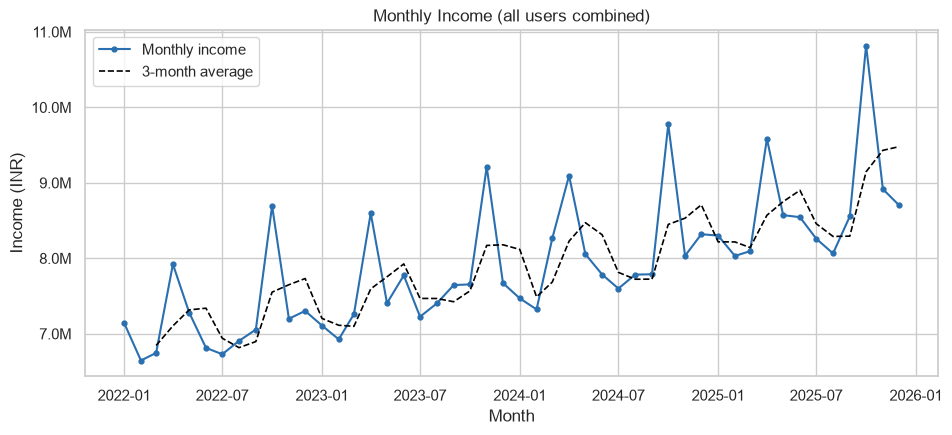

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["income"], color=INCOME_C, marker="o", ms=3.5, label="Monthly income")
ax.plot(monthly.index, monthly["income"].rolling(3).mean(), color="black", ls="--", lw=1.2, label="3-month average")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(inr))
ax.set(title="Monthly Income (all users combined)", xlabel="Month", ylabel="Income (INR)")
ax.legend()
plt.show(); save(fig, "01_monthly_income.png")

The solid line is total income each month; the dashed line is a 3-month moving average that smooths short-term ups and downs so the underlying trend is easier to see.

## 6. Expense Analysis
Expenses are completed `expense` transactions **minus refunds** (a refund gives money back for an earlier purchase). Transfers to savings products are not expenses.

In [14]:
total_expenses = monthly["net_expenses"].sum()
avg_expense_txn = expenses["amount"].mean()
avg_monthly_expenses = monthly["net_expenses"].mean()
print(f"Gross expenses          : INR {expenses['amount'].sum():,.0f}")
print(f"Refunds                 : INR {refunds['amount'].sum():,.0f}")
print(f"Total (net) expenses    : INR {total_expenses:,.0f}")
print(f"Average expense payment : INR {avg_expense_txn:,.2f}")
print(f"Average monthly expenses: INR {avg_monthly_expenses:,.0f}")

top_months = monthly["net_expenses"].nlargest(5)
print("\nTop 5 spending months:")
for d, v in top_months.items():
    print(f"  {d:%b %Y}: INR {v:,.0f}")

Gross expenses          : INR 294,883,929
Refunds                 : INR 2,536,122
Total (net) expenses    : INR 292,347,808
Average expense payment : INR 5,705.52
Average monthly expenses: INR 6,090,579

Top 5 spending months:
  Dec 2025: INR 7,793,468
  May 2025: INR 7,626,812
  Sep 2025: INR 7,441,134
  Oct 2024: INR 7,221,325
  Oct 2025: INR 7,117,448


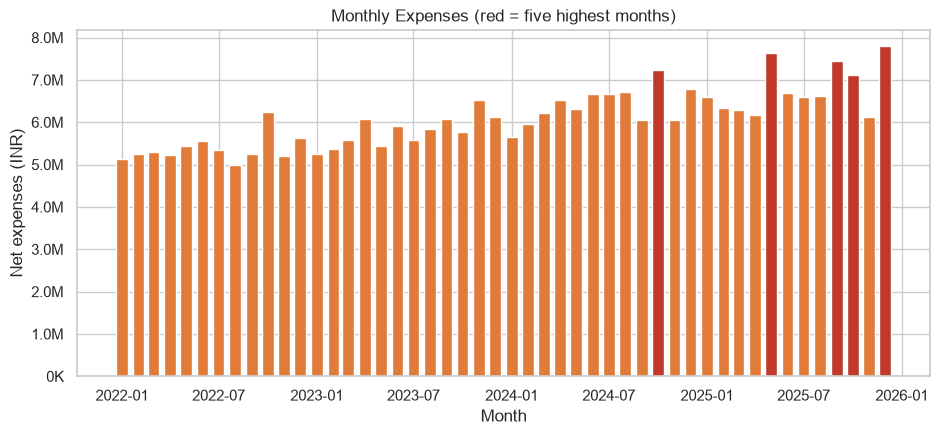

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
colors = [NEG_C if d in top_months.index else EXPENSE_C for d in monthly.index]
ax.bar(monthly.index, monthly["net_expenses"], width=22, color=colors)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(inr))
ax.set(title="Monthly Expenses (red = five highest months)", xlabel="Month", ylabel="Net expenses (INR)")
plt.show(); save(fig, "02_monthly_expenses.png")

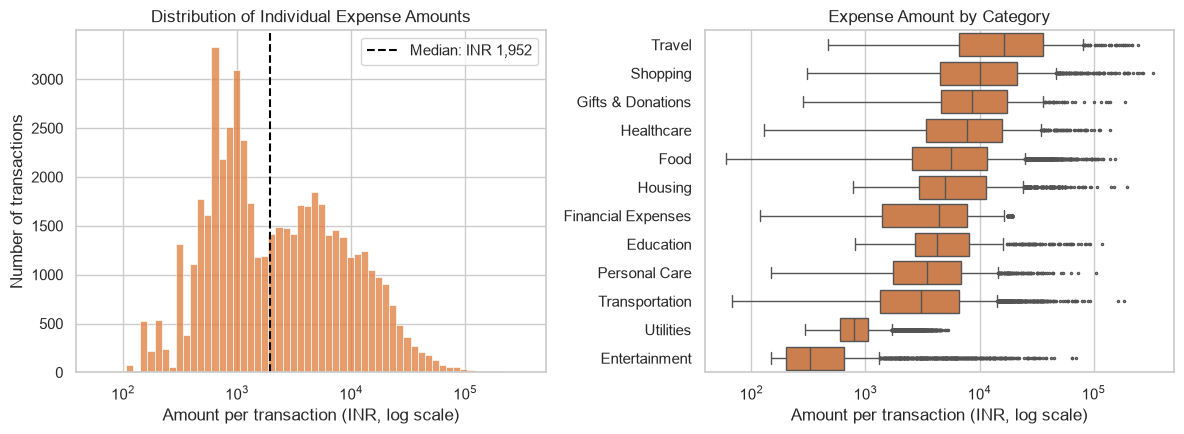

In [16]:
# Expense distribution: how large is a typical single expense? (log scale because a few payments are very large)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(expenses["amount"], bins=60, log_scale=True, color=EXPENSE_C, ax=axes[0])
axes[0].axvline(expenses["amount"].median(), color="black", ls="--", label=f"Median: INR {expenses['amount'].median():,.0f}")
axes[0].set(title="Distribution of Individual Expense Amounts", xlabel="Amount per transaction (INR, log scale)", ylabel="Number of transactions")
axes[0].legend()

order = expenses.groupby("category")["amount"].median().sort_values(ascending=False).index
sns.boxplot(data=expenses, y="category", x="amount", order=order, color=EXPENSE_C, fliersize=1.5, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set(title="Expense Amount by Category", xlabel="Amount per transaction (INR, log scale)", ylabel="")
plt.tight_layout(); plt.show(); save(fig, "03_expense_distribution.png")

**Expense distribution.** Most transactions are small, but a long tail of large payments (shown by the log scale) means the *mean* is much higher than the *median*. The box plot shows which categories have typically large payments (e.g. Travel and Shopping) versus many small ones (e.g. Utilities, Entertainment).

## 7. Savings Analysis
**Savings = Income − Expenses** (expenses net of refunds), per month. A negative value means spending was higher than income that month.

In [17]:
total_savings = monthly["savings"].sum()
print(f"Total savings           : INR {total_savings:,.0f}")
print(f"Average monthly savings : INR {monthly['savings'].mean():,.0f}")
print(f"Overall savings rate    : {100 * total_savings / total_income:.1f}% of income")
print(f"Highest savings month   : {monthly['savings'].idxmax():%b %Y} (INR {monthly['savings'].max():,.0f})")
print(f"Lowest savings month    : {monthly['savings'].idxmin():%b %Y} (INR {monthly['savings'].min():,.0f})")
print(f"Months with positive savings: {(monthly['savings'] > 0).sum()} | negative: {(monthly['savings'] < 0).sum()}")

# Per-user view: how many users spent more than they earned over the whole period?
per_user = pd.DataFrame({"income": income.groupby("user_id")["amount"].sum(),
                         "net_exp": expenses.groupby("user_id")["amount"].sum() - refunds.groupby("user_id")["amount"].sum().reindex(expenses.groupby("user_id").size().index, fill_value=0)}).fillna(0)
per_user["savings"] = per_user["income"] - per_user["net_exp"]
print(f"\nUsers with negative total savings: {(per_user['savings'] < 0).sum()} of {len(per_user)}")

Total savings           : INR 87,716,295
Average monthly savings : INR 1,827,423
Overall savings rate    : 23.1% of income
Highest savings month   : Oct 2025 (INR 3,701,579)
Lowest savings month    : Dec 2025 (INR 908,906)
Months with positive savings: 48 | negative: 0

Users with negative total savings: 17 of 150


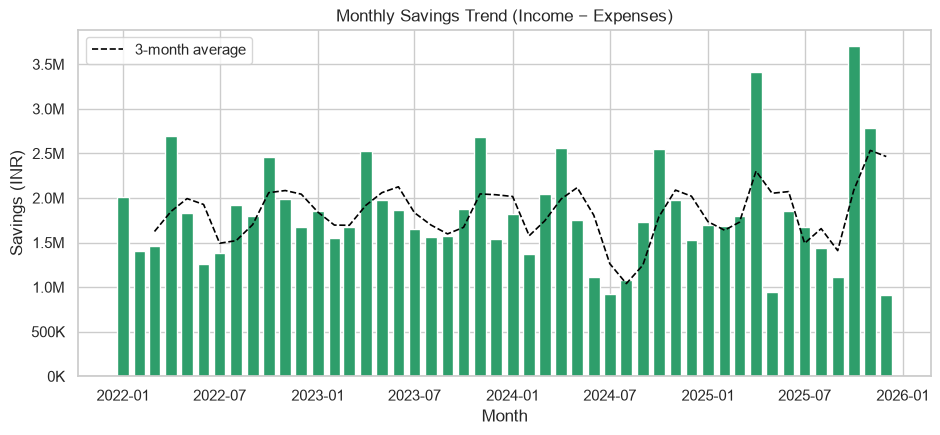

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(monthly.index, monthly["savings"], width=22, color=np.where(monthly["savings"] >= 0, SAVINGS_C, NEG_C))
ax.plot(monthly.index, monthly["savings"].rolling(3).mean(), color="black", ls="--", lw=1.2, label="3-month average")
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(inr))
ax.set(title="Monthly Savings Trend (Income − Expenses)", xlabel="Month", ylabel="Savings (INR)")
ax.legend()
plt.show(); save(fig, "04_monthly_savings.png")

## 8. Category-wise Spending
We use the categories actually present in the dataset (nothing assumed). Spending per category is net of refunds. `Income`, `Transfers` and `Savings and Investments` are not spending categories and are excluded.

In [19]:
cat = (cat_gross - cat_refund).sort_values(ascending=False).to_frame("total_spent")
cat["share_pct"] = 100 * cat["total_spent"] / cat["total_spent"].sum()
cat["transactions"] = expenses.groupby("category").size()
cat["avg_per_transaction"] = cat["total_spent"] / cat["transactions"]
print("Categories in dataset:", ", ".join(cat.index))
print(f"\nHighest spending category: {cat.index[0]} ({cat['share_pct'].iloc[0]:.1f}%)")
print(f"Lowest spending category : {cat.index[-1]} ({cat['share_pct'].iloc[-1]:.1f}%)")
cat

Categories in dataset: Food, Housing, Shopping, Transportation, Healthcare, Utilities, Travel, Financial Expenses, Education, Personal Care, Gifts & Donations, Entertainment

Highest spending category: Food (26.3%)
Lowest spending category : Entertainment (1.8%)


,total_spent,share_pct,transactions,avg_per_transaction
category,,,,
Food,"76,779,716.18",26.26,8405,"9,135.00"
Housing,"68,143,166.00",23.31,7928,"8,595.25"
Shopping,"26,188,599.54",8.96,1386,"18,895.09"
Transportation,"25,865,852.98",8.85,4647,"5,566.14"
Healthcare,"21,833,109.00",7.47,1913,"11,413.02"
Utilities,"15,771,222.39",5.39,17389,906.97
Travel,"14,545,098.64",4.98,503,"28,916.70"
Financial Expenses,"12,890,562.00",4.41,2257,"5,711.37"
Education,"9,603,223.00",3.28,1302,"7,375.75"


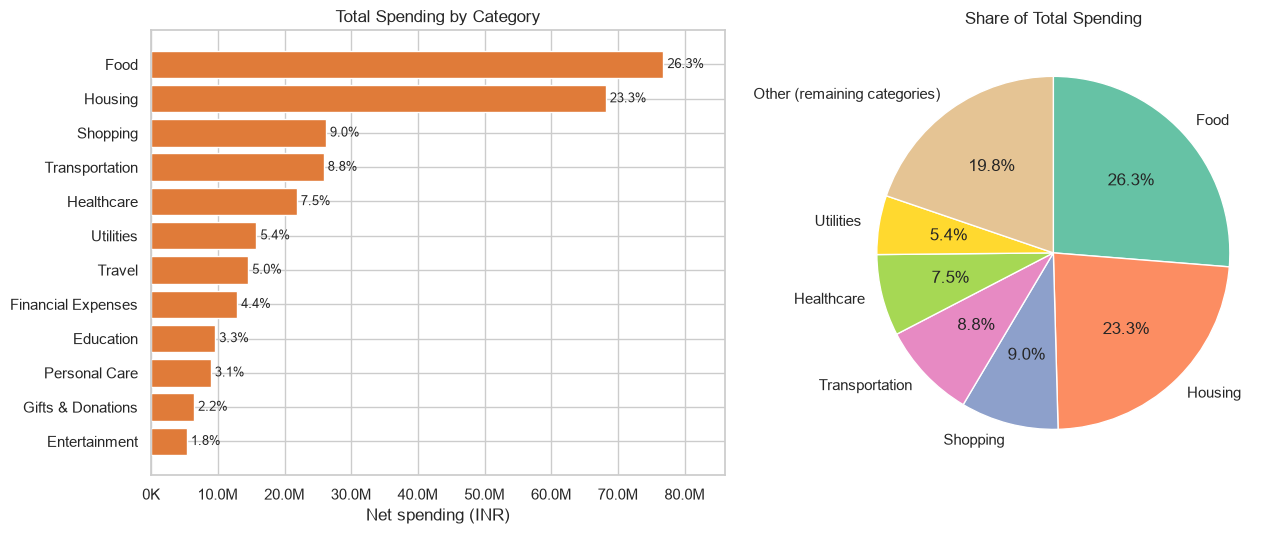

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})

plot_cat = cat.sort_values("total_spent")
bars = axes[0].barh(plot_cat.index, plot_cat["total_spent"], color=EXPENSE_C)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(inr))
for b, p in zip(bars, plot_cat["share_pct"]):
    axes[0].text(b.get_width(), b.get_y() + b.get_height() / 2, f" {p:.1f}%", va="center", fontsize=9)
axes[0].set(title="Total Spending by Category", xlabel="Net spending (INR)", ylabel="")
axes[0].set_xlim(0, plot_cat["total_spent"].max() * 1.12)

# Pie: show the top 6 categories, group the rest as "Other" so small slices stay readable
top_n = 6
pie = cat["total_spent"].head(top_n).copy()
pie["Other (remaining categories)"] = cat["total_spent"].iloc[top_n:].sum()
axes[1].pie(pie, labels=pie.index, autopct="%1.1f%%", startangle=90, counterclock=False,
            colors=sns.color_palette("Set2", len(pie)), wedgeprops={"edgecolor": "white"})
axes[1].set_title("Share of Total Spending")
plt.tight_layout(); plt.show(); save(fig, "05_category_spending.png")

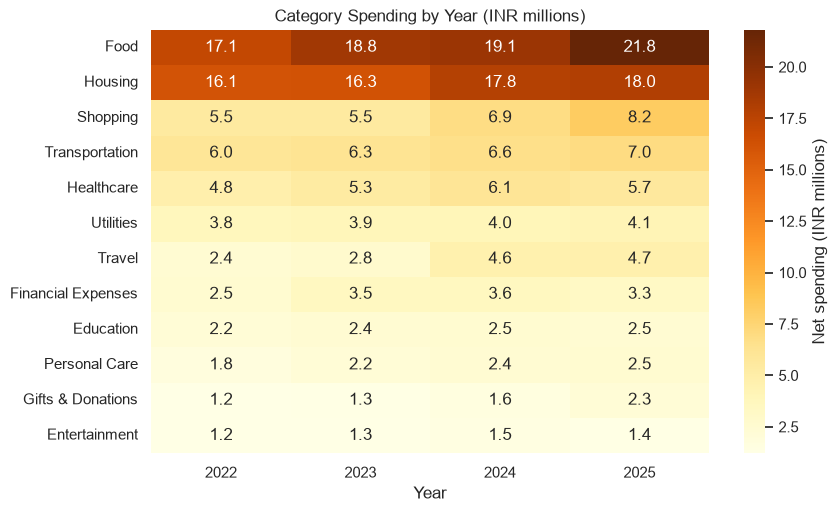

transaction_date,2023 vs prev year (%),2024 vs prev year (%),2025 vs prev year (%)
category,,,
Food,9.70,1.80,14.10
Housing,0.90,9.50,1.00
Shopping,0.70,25.20,19.10
Transportation,4.90,6.20,5.40
Healthcare,11.90,13.20,-6.70
Utilities,3.00,3.50,3.70
Travel,12.80,66.90,2.60
Financial Expenses,39.90,2.90,-9.80
Education,10.40,4.60,-3.30


In [21]:
# Category spending over time: does the mix change by year?
cat_year = (expenses.groupby([expenses.transaction_date.dt.year, "category"])["amount"].sum()
            .sub(refunds.groupby([refunds.transaction_date.dt.year, "category"])["amount"].sum(), fill_value=0)
            .unstack(0))
cat_year = cat_year.loc[cat.index]
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(cat_year / 1e6, annot=True, fmt=".1f", cmap="YlOrBr", cbar_kws={"label": "Net spending (INR millions)"}, ax=ax)
ax.set(title="Category Spending by Year (INR millions)", xlabel="Year", ylabel="")
plt.show(); save(fig, "06_category_by_year_heatmap.png")
(cat_year.pct_change(axis=1) * 100).round(1).iloc[:, 1:].rename(columns=lambda y: f"{y} vs prev year (%)")

## 9. Monthly Trends
Income, expenses and savings together, so months can be compared directly.

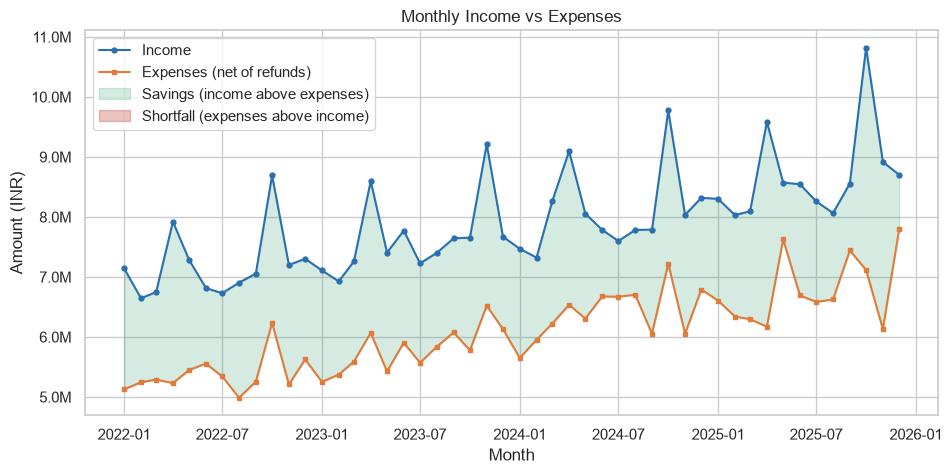

In [22]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(monthly.index, monthly["income"], color=INCOME_C, marker="o", ms=3.5, label="Income")
ax.plot(monthly.index, monthly["net_expenses"], color=EXPENSE_C, marker="s", ms=3.5, label="Expenses (net of refunds)")
ax.fill_between(monthly.index, monthly["net_expenses"], monthly["income"],
                where=monthly["income"] >= monthly["net_expenses"], color=SAVINGS_C, alpha=0.2, label="Savings (income above expenses)")
ax.fill_between(monthly.index, monthly["net_expenses"], monthly["income"],
                where=monthly["income"] < monthly["net_expenses"], color=NEG_C, alpha=0.3, label="Shortfall (expenses above income)")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(inr))
ax.set(title="Monthly Income vs Expenses", xlabel="Month", ylabel="Amount (INR)")
ax.legend(loc="upper left")
plt.show(); save(fig, "07_monthly_income_vs_expenses.png")

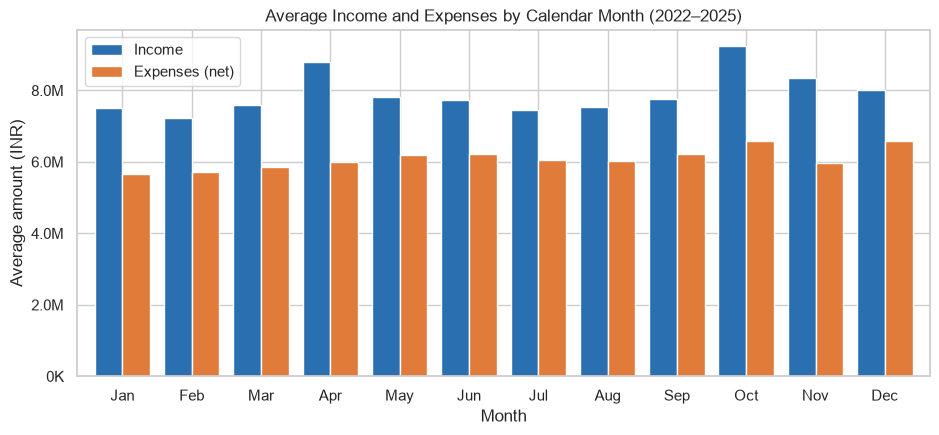

In [23]:
# Which calendar months are typically high-spend? (average across the years)
seasonal = monthly.groupby(monthly.index.month)[["income", "net_expenses"]].mean()
seasonal.index = [calendar.month_abbr[m] for m in seasonal.index]
fig, ax = plt.subplots(figsize=(11, 4.5))
seasonal.plot.bar(ax=ax, color=[INCOME_C, EXPENSE_C], width=0.8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(inr))
ax.set(title="Average Income and Expenses by Calendar Month (2022–2025)", xlabel="Month", ylabel="Average amount (INR)")
ax.legend(["Income", "Expenses (net)"]); plt.xticks(rotation=0)
plt.show(); save(fig, "08_seasonal_pattern.png")

In [24]:
# Month-over-month changes and unusual months (more than 2 standard deviations from the typical month-to-month change)
chg = monthly["net_expenses"].pct_change() * 100
z = (chg - chg.mean()) / chg.std()
unusual = monthly.assign(expense_change_pct=chg, z_score=z)[z.abs() > 2][["net_expenses", "expense_change_pct", "z_score"]]
print("Biggest month-over-month increases in expenses:")
print(chg.nlargest(3).round(1).rename(lambda d: f"{d:%b %Y}").to_string())
print("\nBiggest month-over-month decreases:")
print(chg.nsmallest(3).round(1).rename(lambda d: f"{d:%b %Y}").to_string())
print("\nUnusual months (|z| > 2):")
unusual

Biggest month-over-month increases in expenses:
month
Dec 2025   27.10
May 2025   23.60
Oct 2024   19.30

Biggest month-over-month decreases:
month
Nov 2022   -16.50
Nov 2024   -16.20
Nov 2025   -13.80

Unusual months (|z| > 2):


,net_expenses,expense_change_pct,z_score
month,,,
2025-05-01,"7,626,811.59",23.61,2.32
2025-12-01,"7,793,467.99",27.09,2.69


In [25]:
yearly = monthly.groupby(monthly.index.year)[["income", "net_expenses", "savings"]].sum()
yearly["savings_rate_pct"] = 100 * yearly["savings"] / yearly["income"]
yearly["expense_growth_pct"] = yearly["net_expenses"].pct_change() * 100
yearly

,income,net_expenses,savings,savings_rate_pct,expense_growth_pct
month,,,,,
2022,"86,439,622.00","64,552,809.86","21,886,812.14",25.32,NaN
2023,"91,885,406.00","69,529,252.94","22,356,153.06",24.33,7.71
2024,"97,292,241.00","76,842,659.51","20,449,581.49",21.02,10.52
2025,"104,446,834.00","81,423,085.42","23,023,748.58",22.04,5.96


## 10. Financial Summary
Every value below is calculated from the data above.

In [26]:
summary = pd.Series({
    "Period": f"{monthly.index.min():%b %Y} - {monthly.index.max():%b %Y}",
    "Users": df["user_id"].nunique(),
    "Total income (INR)": total_income,
    "Total expenses, net of refunds (INR)": total_expenses,
    "Total savings (INR)": total_savings,
    "Overall savings rate (%)": 100 * total_savings / total_income,
    "Average monthly expenses (INR)": avg_monthly_expenses,
    "Highest spending category": f"{cat.index[0]} ({cat['share_pct'].iloc[0]:.1f}%)",
    "Highest expense month": f"{monthly['net_expenses'].idxmax():%b %Y} (INR {monthly['net_expenses'].max():,.0f})",
    "Highest savings month": f"{monthly['savings'].idxmax():%b %Y} (INR {monthly['savings'].max():,.0f})",
    "Lowest savings month": f"{monthly['savings'].idxmin():%b %Y} (INR {monthly['savings'].min():,.0f})",
}, name="Value")

def fmt(v):
    return f"{v:,.2f}" if isinstance(v, (int, float, np.floating)) and not float(v).is_integer() else (f"{v:,.0f}" if isinstance(v, (int, float, np.floating, np.integer)) else v)
display(summary.map(fmt).to_frame())

# Save shareable outputs for teammates / the dashboard
monthly.rename_axis("month").to_csv(OUT_DIR / "monthly_income_expense_savings.csv")
cat.to_csv(OUT_DIR / "category_spending_summary.csv")
summary.to_csv(OUT_DIR / "financial_summary.csv")
print("Saved CSVs and figures to", OUT_DIR.relative_to(REPO_ROOT))

,Value
Period,Jan 2022 - Dec 2025
Users,150
Total income (INR),"380,064,103"
"Total expenses, net of refunds (INR)","292,347,807.73"
Total savings (INR),"87,716,295.27"
Overall savings rate (%),23.08
Average monthly expenses (INR),"6,090,579.33"
Highest spending category,Food (26.3%)
Highest expense month,"Dec 2025 (INR 7,793,468)"
Highest savings month,"Oct 2025 (INR 3,701,579)"


Saved CSVs and figures to outputs\eda


## 11. Key Insights
The sentences below are generated from the computed numbers, so they always match the data.

In [27]:
first_y, last_y = yearly.index[0], yearly.index[-1]
growth = (yearly.loc[last_y, "net_expenses"] / yearly.loc[first_y, "net_expenses"] - 1) * 100
inc_growth = (yearly.loc[last_y, "income"] / yearly.loc[first_y, "income"] - 1) * 100
top3 = cat.head(3)
months_pos = (monthly["savings"] > 0).sum()
needs_attn = cat_year.pct_change(axis=1).iloc[:, -1].sort_values(ascending=False)
big_move = (cat_year.iloc[:, -1] - cat_year.iloc[:, 0]).sort_values(ascending=False)

insights = [
    f"1. Biggest category: {cat.index[0]} takes {cat['share_pct'].iloc[0]:.1f}% of all spending; the top three ({', '.join(top3.index)}) together account for {top3['share_pct'].sum():.1f}%.",
    f"2. Smallest category: {cat.index[-1]} ({cat['share_pct'].iloc[-1]:.1f}%).",
    f"3. Expenses vs time: yearly expenses moved from INR {yearly.loc[first_y,'net_expenses']:,.0f} in {first_y} to INR {yearly.loc[last_y,'net_expenses']:,.0f} in {last_y} ({growth:+.1f}%), while income changed by {inc_growth:+.1f}%.",
    f"4. Income vs expenses: income exceeded expenses in {months_pos} of {len(monthly)} months; overall {100*total_savings/total_income:.1f}% of income was left after spending.",
    f"5. Highest spending month: {monthly['net_expenses'].idxmax():%b %Y} (INR {monthly['net_expenses'].max():,.0f}), {100*(monthly['net_expenses'].max()/avg_monthly_expenses-1):.1f}% above the average month.",
    f"6. Seasonality: on average {seasonal['net_expenses'].idxmax()} is the highest-spending calendar month and {seasonal['net_expenses'].idxmin()} the lowest.",
    f"7. Categories to watch: {big_move.index[0]} grew the most in rupees between {cat_year.columns[0]} and {cat_year.columns[-1]} (+INR {big_move.iloc[0]:,.0f}); {needs_attn.index[0]} had the fastest growth in {cat_year.columns[-1]} ({needs_attn.iloc[0]*100:+.1f}% vs previous year).",
    f"8. Individuals: {(per_user['savings'] < 0).sum()} of {len(per_user)} users spent more than they earned over the full period, so the combined view hides differences between users.",
]
print("\n".join(insights))

1. Biggest category: Food takes 26.3% of all spending; the top three (Food, Housing, Shopping) together account for 58.5%.
2. Smallest category: Entertainment (1.8%).
3. Expenses vs time: yearly expenses moved from INR 64,552,810 in 2022 to INR 81,423,085 in 2025 (+26.1%), while income changed by +20.8%.
4. Income vs expenses: income exceeded expenses in 48 of 48 months; overall 23.1% of income was left after spending.
5. Highest spending month: Dec 2025 (INR 7,793,468), 28.0% above the average month.
6. Seasonality: on average Oct is the highest-spending calendar month and Jan the lowest.
7. Categories to watch: Food grew the most in rupees between 2022 and 2025 (+INR 4,702,794); Gifts & Donations had the fastest growth in 2025 (+39.4% vs previous year).
8. Individuals: 17 of 150 users spent more than they earned over the full period, so the combined view hides differences between users.


**Caveats.** The data is synthetic, so patterns reflect how it was generated, not real households. Figures combine all 150 users; individual users can look quite different. This section describes what happened — it does not give financial advice.

## 12. Conclusion
This EDA describes the spending behaviour in the dataset: how much comes in, where it goes, how much is left, and how this changes by month, year and category. The outputs help the rest of the project:

- **Forecasting:** the monthly trend and seasonal charts show which patterns (category weight, high-spend months, year-on-year growth) a model needs to capture.
- **Dashboard:** `outputs/eda/monthly_income_expense_savings.csv`, `category_spending_summary.csv` and `financial_summary.csv` are ready-to-use summary tables, and the charts are in `outputs/eda/figures/`.
- **Data quality:** the cleaned file passed all checks (no duplicates, valid positive amounts, consistent types and categories); only failed payments were excluded from totals, as the dataset specifies.